<table style="width: 100%;">
  <tr>
    <td style="text-align: left; vertical-align: middle;">
        <h1 style="margin: 0;">Deep Learning's Assignment 2</h1>
        <h4 style="margin: 0;">Prof. Bahrak</h4>
        <h4 style="margin: 0;">Authors: Erfan Ahmadi, Mohammad Ali Olama</h4>
        <h4 style="margin: 0;">[Group work]</h4>
    </td>
    <td style="text-align: right; vertical-align: middle;">
      <img src="https://media.porsline.ir/images/1642313491sktwifppujekhvh" alt="CC" width="1000">
    </td>
  </tr>
</table>



#Question 1

Part 1.1 is only descriptions

## Q1.2

### Preprocessing Steps in the Paper

The paper performs several preprocessing steps on the HAM10000 dataset to ensure that the images are in a suitable format for training the CNN model. Below is a detailed explanation of each step along with the reasons why they are vital.

---

#### 1. Image Resizing

- **What It Is:**  
  Each dermatoscopic image is resized to a uniform dimension. This ensures that every image fed into the CNN model has the same shape and size.

- **Why It Is Vital:**  
  - **Consistency:** Uniform dimensions allow the CNN to apply filters and pooling operations consistently across all inputs.
  - **Efficient Computation:** A fixed input size simplifies the network architecture, reducing computational complexity during both training and inference.
  - **Feature Extraction:** Standardizing image dimensions helps the model extract features systematically from each sample.

---

#### 2. Normalization

- **What It Is:**  
  Normalization involves scaling the pixel values of images, originally in the range of 0 to 255, to a range between 0 and 1. This is typically achieved by dividing each pixel value by 255.

- **Why It Is Vital:**  
  - **Improved Convergence:** Scaling the pixel values leads to smoother gradient flow, enabling faster and more stable convergence during training.
  - **Balanced Learning:** It reduces the variance in the input data, ensuring that larger pixel values do not dominate the learning process.
  - **Stability:** Normalization prevents numerical instabilities during matrix computations in the CNN.

---

#### 3. Data Augmentation

- **What It Is:**  
  Data augmentation applies a variety of transformations—such as rotations, zooming, flipping, shearing, and brightness adjustments—to the original images. This process artificially increases the diversity of the training dataset.

- **Why It Is Vital:**  
  - **Handling Class Imbalance:** The HAM10000 dataset comprises multiple skin lesion categories that might not be equally represented. Augmentation helps balance the dataset by generating more varied examples.
  - **Generalization:** Exposure to different image variations (e.g., changes in orientation or lighting) enhances the model's ability to generalize to unseen data.
  - **Overfitting Prevention:** By increasing the diversity of training samples, data augmentation serves as a regularization technique, reducing the risk of overfitting.

---

#### Summary

The preprocessing steps—**image resizing**, **normalization**, and **data augmentation**—are essential for preparing the dermatoscopic images from the HAM10000 dataset. They ensure that the input data is consistent, appropriately scaled, and diversified, which in turn improves the performance, generalization, and robustness of the CNN model for skin lesion classification.

*Citations:*  
:contentReference[oaicite:0]{index=0}


## Import libraries


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Dense, Dropout, InputLayer, Flatten
from tensorflow.keras.regularizers import l2
from sklearn.metrics import confusion_matrix
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

Fix the random seed to make reconstruction possible

In [ ]:
tf.random.set_seed(42)

Mount the Drive to access the data

In [ ]:
import os
from google.colab import drive
from IPython.display import clear_output

drive.mount('/content/drive')
os.environ['KAGGLE_CONFIG_DIR'] = "/content/drive/MyDrive/Kaggle"


Mounted at /content/drive


Download the dataset

In [ ]:
# # !pip uninstall -y kaggle
# # !pip install --upgrade pip
# # !pip install kaggle==1.5.6
# !kaggle -v

# # ! pip install plotly --upgrade
# !pip install jupyter-dash

# clear_output()

Unzip

In [ ]:
# # ! kaggle datasets download -d rm1000/skin-cancer-isic-images
# !unzip skin-cancer-isic-images.zip

Move to drive

In [ ]:
# # !cp -r /content/skin-cancer-isic-images.zip /content/drive/MyDrive/TEIAS/Deep/HW2/datasets/skin-cancer-isic-images.zip
# !unzip /content/drive/MyDrive/TEIAS/Deep/HW2/datasets/skin-cancer-isic-images.zip -d /content/drive/MyDrive/TEIAS/Deep/HW2/datasets/

Load the data from Directory using Image Generator

In [ ]:
# from tensorflow.keras.preprocessing.image import ImageDataGenerator

# # Define the path to your dataset
# train_data_dir = '/content/drive/MyDrive/TEIAS/Deep/HW2/datasets/'

# # Create an ImageDataGenerator without any augmentation
# datagen = ImageDataGenerator()

# # Load the training data without augmentation
# train_generator = datagen.flow_from_directory(
#     train_data_dir,
#     batch_size=32,
#     class_mode='binary',
#     shuffle=True
# )
# print(train_generator.class_indices)

# # train test validation split.20 percent test 20 percent validation




In [ ]:
# print(train_generator.samples)
# print(train_generator.classes)

In this part because of large number of **IO opperations** we decided to concatenate the images togheter and save them in just 1 file. Therefore we don't need to wait a lot for loading all of the images. We can read them directly from 1 file

In [ ]:
# from sklearn.model_selection import train_test_split
# import numpy as np
# import tensorflow as tf
# from tensorflow.keras.preprocessing.image import ImageDataGenerator
# from tqdm import tqdm

# # Get images and labels from the train_generator
# images, labels = [], []
# for img, label in tqdm(train_generator):
#     images.append(img)
#     labels.append(label)
#     if len(images) * train_generator.batch_size >= train_generator.samples:
#         break

# images = np.concatenate(images)
# labels = np.concatenate(labels)




In [ ]:
# print(images.shape)
# labels.shape

In [ ]:

# import numpy as np


# # Save the array to a .npy file
# np.save('/content/drive/MyDrive/TEIAS/Deep/HW2/images_array1.npy', images)
# np.save('/content/drive/MyDrive/TEIAS/Deep/HW2/labels_array1.npy', labels)


Codes were executed once so we don't need to run them again and we commented them. (Uncomment them if you wanted to run them)

In [ ]:
import numpy as np
# Load the saved NumPy arrays
images = np.load('/content/drive/MyDrive/TEIAS/Deep/HW2/images_array1.npy')
labels = np.load('/content/drive/MyDrive/TEIAS/Deep/HW2/labels_array1.npy')

print(images.shape)
labels.shape


(3297, 256, 256, 3)


(3297,)

The shape is whowing that we have all 3297 samples that each of them is a 256 * 256 image

In [ ]:
labels = labels.astype(int)
labels


array([0, 0, 0, ..., 0, 0, 0])

Train Test Split :

### Exploratory Data Analysis (EDA) for a Limited Image Dataset

 Here are some EDA techniques that can be used:

---

#### 1. Class Distribution Analysis

- **Objective:**  
  Determine if the classes are balanced or if there is a class imbalance issue.
  
- **Methods:**  
  - We have done this in the previous sections on the whole dataset.

---


In [ ]:

import plotly.express as px

# Count the occurrences of each class
class_counts = np.bincount(labels)

# Create a DataFrame for Plotly
import pandas as pd
class_df = pd.DataFrame({'Class': np.arange(len(class_counts)), 'Count': class_counts})


# Create the bar plot using Plotly Express
fig = px.bar(class_df, x='Class', y='Count', title='Distribution of Classes in Labels',
             labels={'Class': 'Class Label', 'Count': 'Number of Samples'})
fig.show()



#### 2. Sample Image Visualization

- **Objective:**  
  Get a visual feel for the images in the dataset and assess their quality and diversity.
  
- **Methods:**  
  - Display a few random samples from each class.
  - Create a grid of images for each category to observe variations in appearance.

---


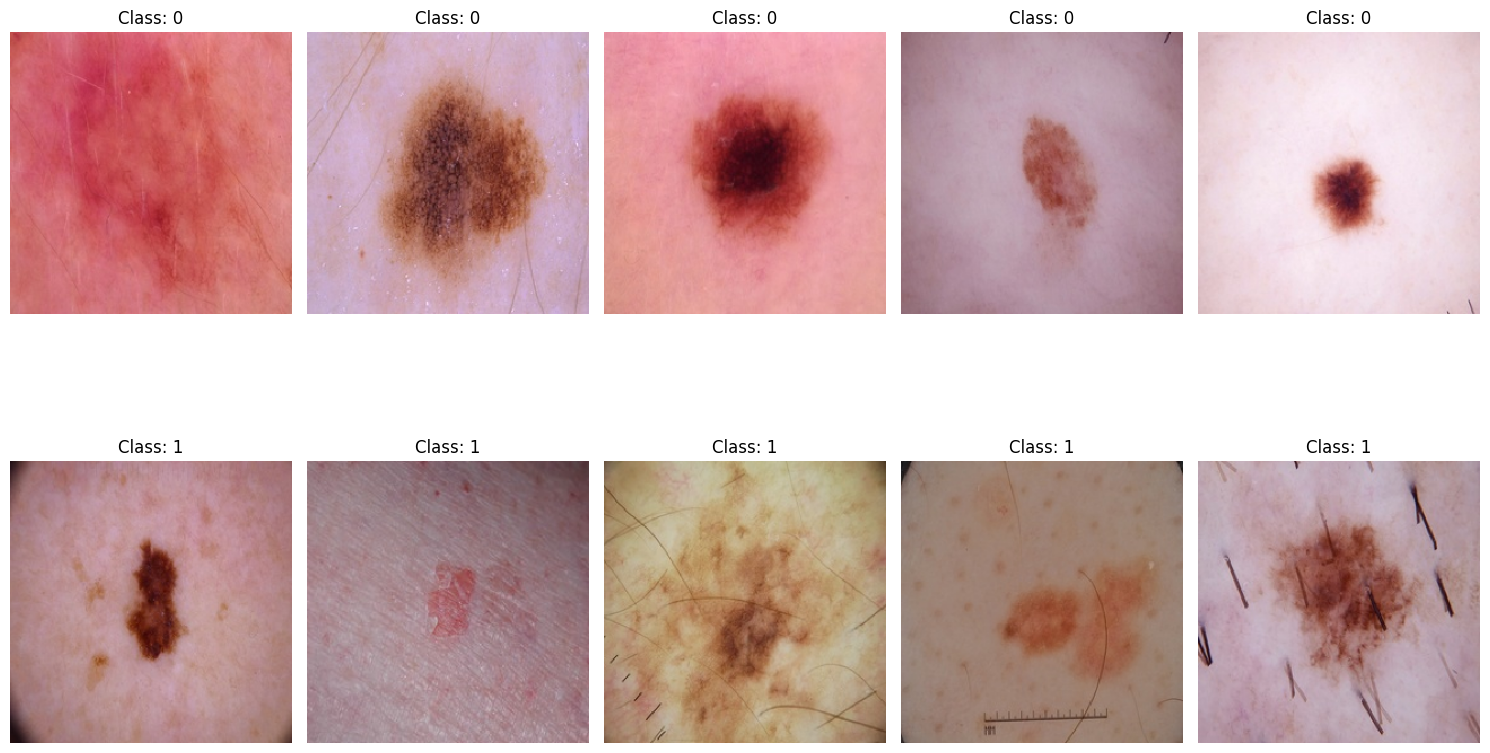

In [ ]:
# Number of samples to plot per class
num_samples_per_class = 5

# Unique classes in y_train
unique_classes = np.unique(labels)

# Create subplots
fig, axes = plt.subplots(len(unique_classes), num_samples_per_class, figsize=(15, 10))

for class_index, class_label in enumerate(unique_classes):
    class_indices = np.where(labels == class_label)[0]
    selected_indices = np.random.choice(class_indices, size=num_samples_per_class, replace=False)

    for i, index in enumerate(selected_indices):
      axes[class_index, i].imshow(images[index] / 255.)
      axes[class_index, i].set_title(f"Class: {class_label}")
      axes[class_index, i].axis('off')

plt.tight_layout()
plt.show()


#### 3. Image Dimension and Size Analysis

- **Objective:**  
  Understand the consistency of image dimensions, which is crucial for preprocessing and model input.
  
- **Methods:**  
  - Extract and plot the distribution of image widths and heights.
  - Check if images need to be resized to a common dimension.

---


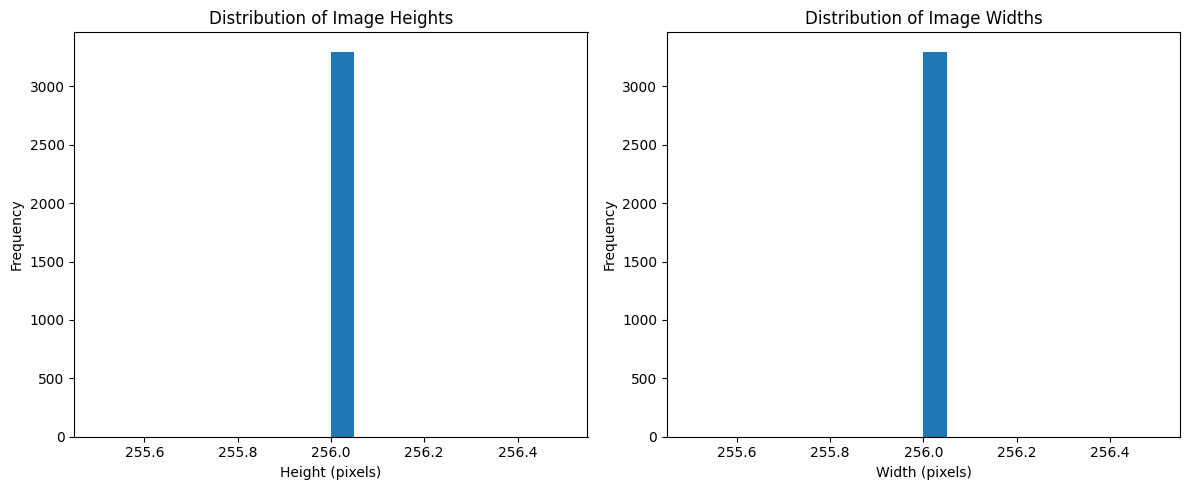

In [ ]:

# Extract image dimensions (height and width)
image_heights = [image.shape[0] for image in images]
image_widths = [image.shape[1] for image in images]

# Create a figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot the distribution of image heights
axes[0].hist(image_heights, bins=20)
axes[0].set_title('Distribution of Image Heights')
axes[0].set_xlabel('Height (pixels)')
axes[0].set_ylabel('Frequency')

# Plot the distribution of image widths
axes[1].hist(image_widths, bins=20)
axes[1].set_title('Distribution of Image Widths')
axes[1].set_xlabel('Width (pixels)')
axes[1].set_ylabel('Frequency')

# Adjust layout and show the plots
plt.tight_layout()
plt.show()


This is an obvious result, Since the dataset is a cleaned version of this data!




#### 4. Pixel Intensity Distribution

- **Objective:**  
  Evaluate the brightness, contrast, and overall pixel intensity distribution.
  
- **Methods:**  
  - Plot histograms of pixel intensities for a random subset of images.
  - Analyze the distribution to decide on normalization strategies.

---

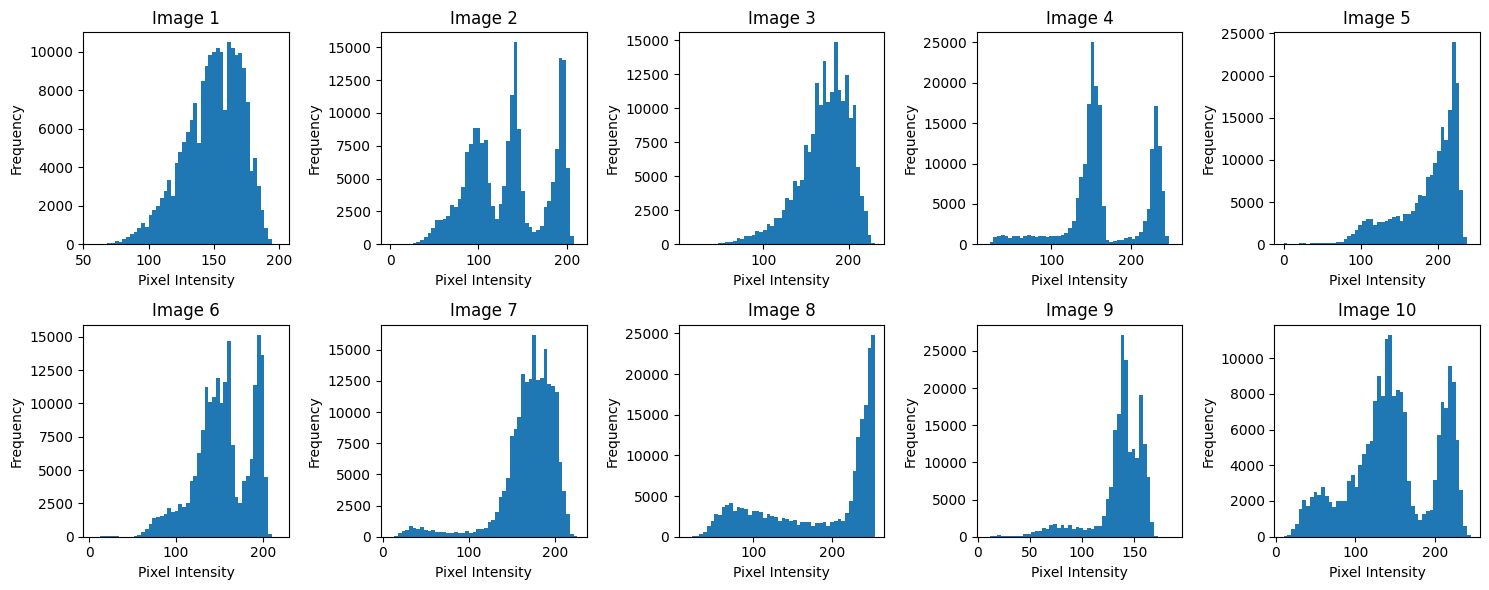

In [ ]:

import matplotlib.pyplot as plt


# Select a random subset of images (e.g., 10 images)
num_images_to_plot = 10
random_indices = np.random.choice(len(images), size=num_images_to_plot, replace=False)
selected_images = images[random_indices]


# Create subplots for each image
fig, axes = plt.subplots(2, 5, figsize=(15, 6))  # Adjust figure size as needed
axes = axes.ravel()  # Flatten the axes array

for i in range(num_images_to_plot):
    # Plot the pixel intensity histogram for the current image
    axes[i].hist(selected_images[i].flatten(), bins=50) # range=(0,1) because of normalization
    axes[i].set_title(f"Image {i+1}")
    axes[i].set_xlabel("Pixel Intensity")
    axes[i].set_ylabel("Frequency")

plt.tight_layout()  # Adjust spacing between subplots
plt.show()


If we normalize the input images (divide by 255.) the distribution won't change!

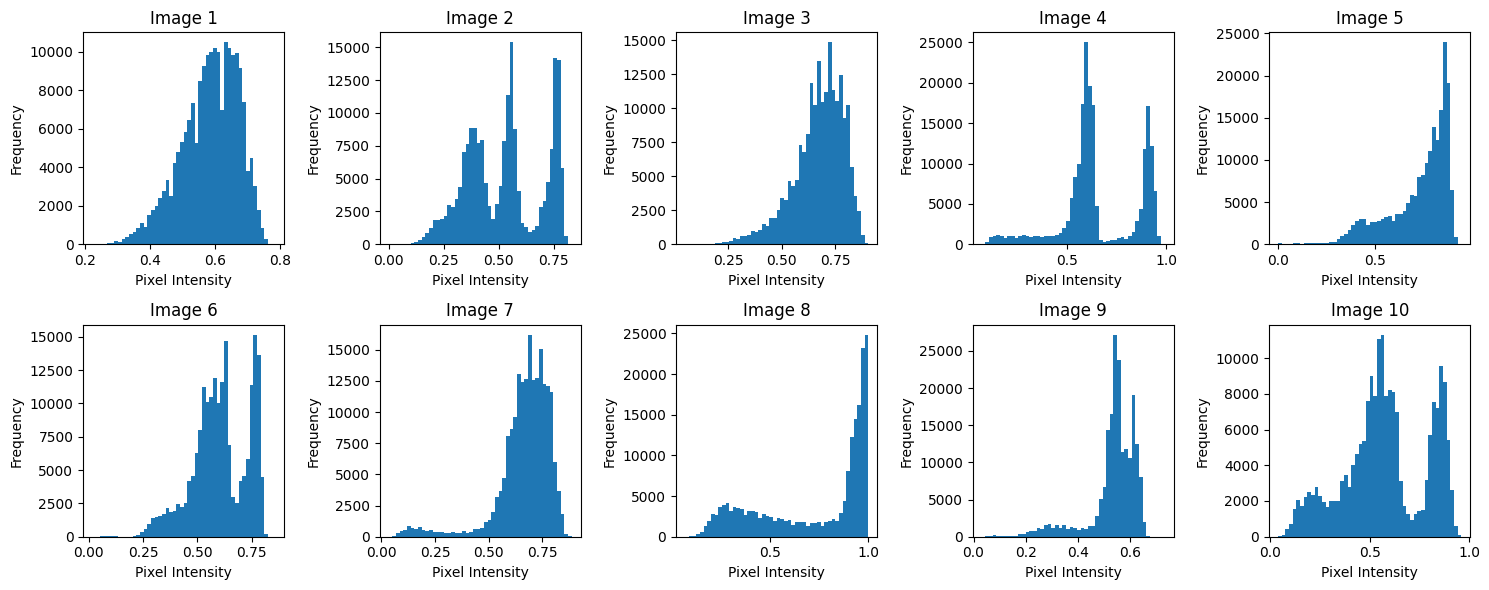

In [ ]:
# Create subplots for each image
fig, axes = plt.subplots(2, 5, figsize=(15, 6))  # Adjust figure size as needed
axes = axes.ravel()  # Flatten the axes array

for i in range(num_images_to_plot):
    # Plot the pixel intensity histogram for the current image
    axes[i].hist(selected_images[i].flatten() / 255., bins=50) # range=(0,1) because of normalization
    axes[i].set_title(f"Image {i+1}")
    axes[i].set_xlabel("Pixel Intensity")
    axes[i].set_ylabel("Frequency")

plt.tight_layout()  # Adjust spacing between subplots
plt.show()

## Q1.3
Some part of this text is from the original paper:

*Dataset augmentation is a critical strategy in machine
learning that enriches training data diversity, particularly vital in image processing. By applying specific
transformations like rotation, zooming, flipping, shearing, and brightness adjustment, we can increase the diversity of our training data, therefore broadening the model’s exposure to potential data variations it might. encounter post-deployment. These transformations not
only enhance the model’s ability to generalize across
new, unseen data, thereby improving its predictive
accuracy, but also serve as a regularization technique,
significantly reducing the risk of overfitting. Through dataset augmentation, the model’s robustness and adaptability is
ensured, reinforcing its performance stability across
a spectrum of conditions, leading to more reliable and
accurate predictions in practical applications. Together,
these preprocessing steps form an integral part of the
data preparation pipeline, setting a strong foundation
for the subsequent training of the CNN model.*

Firstly We want to resize the images

In [ ]:

import tensorflow as tf

resized_images = tf.image.resize(images, (28, 28))

resized_images.shape


TensorShape([3297, 28, 28, 3])

In [ ]:
resized_images = resized_images.numpy()

Spliting Dataset

In [ ]:
# Split data into train, validation, and test sets
from sklearn.model_selection import train_test_split
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tqdm import tqdm

X_train, X_temp, y_train, y_temp , X_train_org , X_temp_org = train_test_split(resized_images, labels,images, test_size=0.2, stratify=labels, random_state=42)  # 80% train, 20% temp (val + test)
X_val, X_test, y_val, y_test, X_val_org , X_test_org  = train_test_split(X_temp, y_temp, X_temp_org,  stratify=y_temp, test_size=0.5, random_state=42)  # Split temp into 50% val, 50% test


# Create ImageDataGenerators for each dataset
datagen_train = ImageDataGenerator()
datagen_val = ImageDataGenerator()
datagen_test = ImageDataGenerator()

train_generator = datagen_train.flow(X_train, y_train, batch_size=32, shuffle=True)
val_generator = datagen_val.flow(X_val, y_val, batch_size=32, shuffle=False)
test_generator = datagen_test.flow(X_test, y_test, batch_size=32, shuffle=False)

In [ ]:
print(X_train_org.shape)

(2637, 256, 256, 3)


Plot histogram of y_train, y_valid, y_test in 3 subplots using plotly

In [ ]:

import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

fig = make_subplots(rows=1, cols=3, subplot_titles=('y_train', 'y_val', 'y_test'))

fig.add_trace(go.Histogram(x=y_train, name='y_train'), row=1, col=1)
fig.add_trace(go.Histogram(x=y_val, name='y_val'), row=1, col=2)
fig.add_trace(go.Histogram(x=y_test, name='y_test'), row=1, col=3)

fig.update_layout(title_text="Histograms of Class Distributions",
                  barmode='overlay',  # Overlay histograms for better comparison
                  bargap=0.1)  # Adjust gap between bars for better visualization

fig.show()


Thus the stratified sampling performs well in creating three datasets.

Now we are going to augument the data. Notice that this process should only be applied to **Training Data**. This process in Keras has a tricky approach. It doesn't create additional augumented data in advance, rather during the training phase, when we load a batch from generator, it applies some modifications (like rotation,...) randomly on that batch. Therefore, in different epochs, different transformations are applied to a specific Batch, which is somehow equal to generating extra dataset in advance.

Create an ImageDataGenerator

In [ ]:
# Create an ImageDataGenerator for training data with augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,                # Normalize pixel values to the [0, 1] range
    rotation_range=20,            # Randomly rotate images by up to ±20 degrees
    width_shift_range=0.2,        # Randomly shift images horizontally by up to 20% of width
    height_shift_range=0.2,       # Randomly shift images vertically by up to 20% of height
    shear_range=0.2,              # Apply random shear transformations (slant the image)
    zoom_range=0.2,               # Randomly zoom in or out by up to 20%
    horizontal_flip=True,         # Randomly flip images horizontally (left-right)
    fill_mode='nearest'           # Fill in missing pixels after transformation using nearest pixel values
)

val_datagen = ImageDataGenerator(
    rescale=1./255,                # Normalize pixel values to the [0, 1] range
)
test_datagen = ImageDataGenerator(
    rescale=1./255,                # Normalize pixel values to the [0, 1] range
)

# Load the training data with augmentation
train_generator = train_datagen.flow(
    X_train, y_train,
    batch_size=32,
    shuffle=True
)

val_generator = val_datagen.flow(
    X_val, y_val,
    batch_size=32,
    shuffle=False
)

test_generator = test_datagen.flow(
    X_test, y_test,
    shuffle=False
)


##### **Safe vs Risky Augmentations for Skin Cancer Classification**

**Recommended Augmentations (Geometric Transformations):**
- Include: `rotation`, `horizontal_flip`, `zoom`, `width_shift`, `height_shift`, `shear`
- These preserve the clinical features of skin lesions while introducing variation in position, orientation, and scale.
- They help the model generalize to different image acquisition conditions without altering lesion appearance.

**Avoided Augmentations (Color and Intensity Changes):**
- Include: `brightness`, `contrast`, `saturation`, `hue` adjustments
- Lesion color and texture are critical diagnostic features. Changing them can mislead the model by introducing unrealistic appearances.
- These transformations may reduce clinical reliability and model interpretability.


Plot some samples from each dataset to understand them better

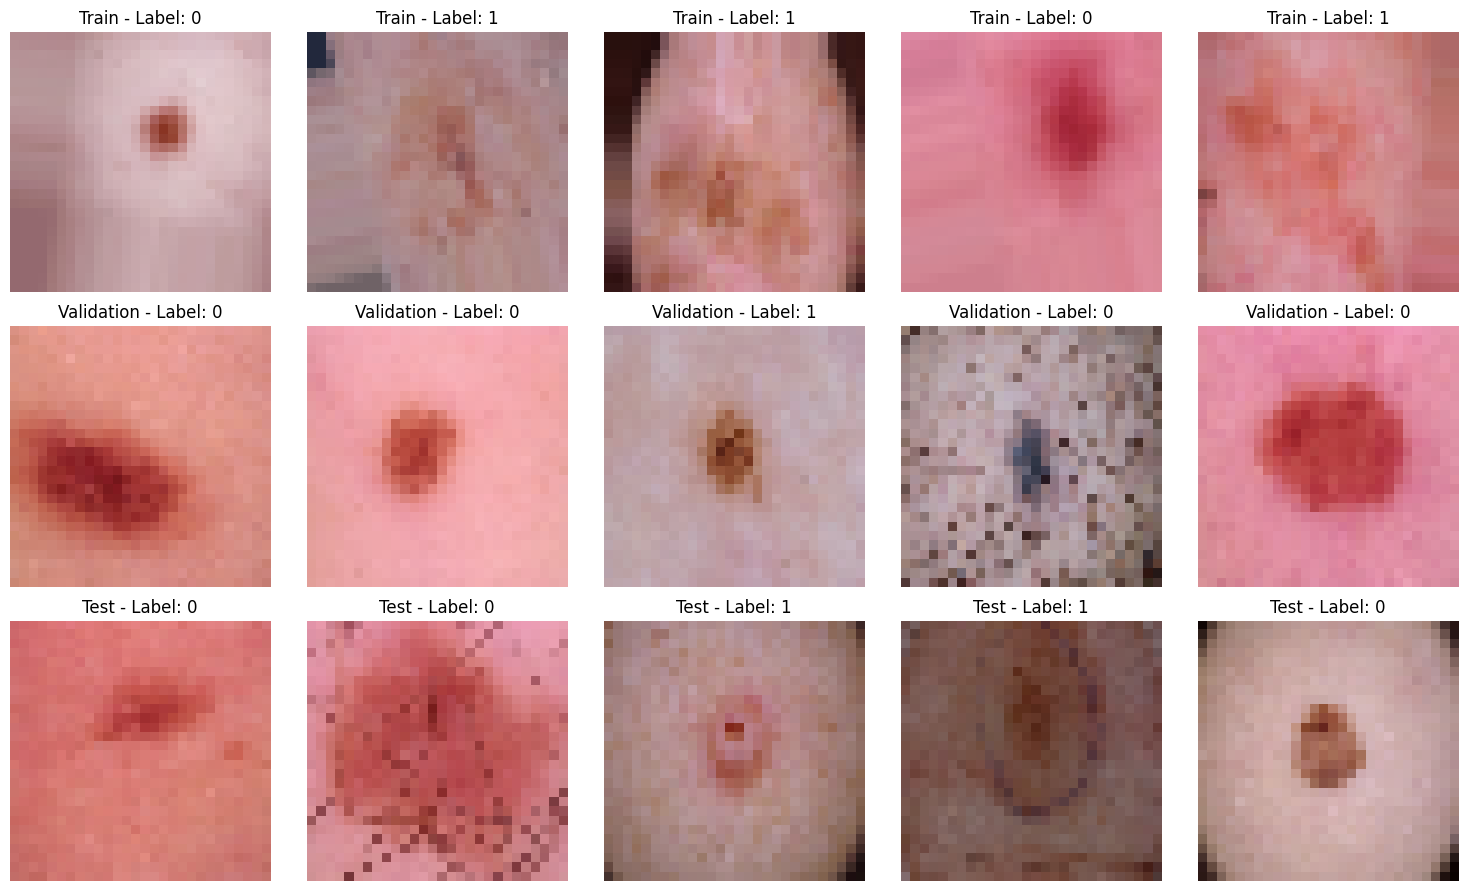

In [ ]:

import matplotlib.pyplot as plt

# Get a batch of images and labels from each generator
train_images, train_labels = next(train_generator)
val_images, val_labels = next(val_generator)
test_images, test_labels = next(test_generator)

# Plot some sample images from each generator
fig, axes = plt.subplots(3, 5, figsize=(15, 9))  # Adjust figure size as needed

for i in range(5):
    axes[0, i].imshow(train_images[i])
    axes[0, i].set_title(f"Train - Label: {train_labels[i]}")
    axes[0, i].axis('off')

    axes[1, i].imshow(val_images[i])
    axes[1, i].set_title(f"Validation - Label: {val_labels[i]}")
    axes[1, i].axis('off')

    axes[2, i].imshow(test_images[i])
    axes[2, i].set_title(f"Test - Label: {test_labels[i]}")
    axes[2, i].axis('off')

plt.tight_layout()
plt.show()


## Q1.4 & Q1.5
Here we are going to implement the base model which is represented in the paper. Notice that we are dealing with a modified version of the original dataset, and our task is a binary classification. So  we change the final last layer of the model. In the original paper, they are using a Dense layer with 7 outputs using softmax activiation function, But we will use a Dense layer with only a single output and sigmoid function. Also, we change the loss to **binary_crossentropy**.

### Building the model according to the paper

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense

def build_cnn_from_table(input_shape=(28, 28, 3), num_classes=2):

    model = Sequential(name="CNN_from_Paper")

    # Input Layer matching the user request
    model.add(Input(shape=input_shape))

    # Layer conv2d_4: Inferred kernel=(3,3), padding='same'
    # Output: (None, 28, 28, 16), Params: (3*3*3+1)*16 = 448
    model.add(Conv2D(16, kernel_size=(3, 3), padding='same', activation='relu', name='conv2d_4'))

    # Layer max_pooling2d_4: Inferred pool_size=(2,2), strides=(2,2)
    # Output: (None, 14, 14, 16), Params: 0
    model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2), name='max_pooling2d_4'))

    # Layer conv2d_5: Inferred kernel=(3,3), padding='same'
    # Output: (None, 14, 14, 32), Params: (3*3*16+1)*32 = 4640
    model.add(Conv2D(32, kernel_size=(3, 3), padding='same', activation='relu', name='conv2d_5'))

    # Layer max_pooling2d_5: Inferred pool_size=(2,2), strides=(2,2)
    # Output: (None, 7, 7, 32), Params: 0
    model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2), name='max_pooling2d_5'))

    # Layer conv2d_6: Inferred kernel=(3,3), padding='same'
    # Output: (None, 7, 7, 64), Params: (3*3*32+1)*64 = 18496
    model.add(Conv2D(64, kernel_size=(3, 3), padding='same', activation='relu', name='conv2d_6'))

    # Layer max_pooling2d_6: Inferred pool_size=(2,2), strides=(2,2), padding='same' to get 4x4 from 7x7
    # Output: (None, 4, 4, 64), Params: 0
    # Note: ceil(7/2)=4. Standard 'valid' padding would give 3x3.
    model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2), padding='same', name='max_pooling2d_6'))

    # Layer conv2d_7: Inferred kernel=(3,3), padding='same'
    # Output: (None, 4, 4, 128), Params: (3*3*64+1)*128 = 73856
    model.add(Conv2D(128, kernel_size=(3, 3), padding='same', activation='relu', name='conv2d_7'))

    # Layer max_pooling2d_7: Inferred pool_size=(2,2), strides=(2,2)
    # Output: (None, 2, 2, 128), Params: 0
    model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2), name='max_pooling2d_7'))

    # Layer flatten_1: Flattens the output of the last pooling layer
    # Output: (None, 2*2*128=512), Params: 0
    model.add(Flatten(name='flatten_1'))

    # Layer dense_3: Fully connected layer
    # Output: (None, 64), Params: (512+1)*64 = 32832
    model.add(Dense(64, activation='relu', name='dense_3'))

    # Layer dense_4: Fully connected layer
    # Output: (None, 32), Params: (64+1)*32 = 2080
    model.add(Dense(32, activation='relu', name='dense_4'))

    # Layer dense_5: Output layer
    # Output: (None, 2), Params: (32+1)*1 = 33
    model.add(Dense(1, activation='sigmoid', name='dense_5'))

    return model

# Build the model
model = build_cnn_from_table(input_shape=(28, 28, 3), num_classes=2)

# Print the model summary to verify the architecture
model.summary()

Model: "CNN_from_Paper"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)                    │ (None, 28, 28, 16)          │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 14, 14, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 14, 14, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 7, 7, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (None, 7, 7, 64)            │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_6 (MaxPooling2D)       │ (None, 4, 4, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 4, 4, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_7 (MaxPooling2D)       │ (None, 2, 2, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 64)                  │          32,832 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 132,385 (517.13 KB)

 Trainable params: 132,385 (517.13 KB)

 Non-trainable params: 0 (0.00 B)

The model summary shows that our implementation is the same as the table presented in the paper.(Notice the number of parameters)

The paper used **Adam** optimizer. Since **they didn't specify the initial learning rate**, we haven't set any initial lr either, and the default lr will be used!

In [ ]:
optimizer = tf.keras.optimizers.Adam()

It is mentioned in the paper that they are Using these two callback! **However, they didn't mention specific hyperparameters of these callback!** Here, we set the hyperparameters manualy.

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Stop training if val_loss doesn't improve for 10 epochs
early_stopping = EarlyStopping(
    monitor='val_accuracy',
    patience=10,
    restore_best_weights=True
)

# Reduce learning rate if val_loss plateaus
reduce_lr = ReduceLROnPlateau(
    monitor='val_accuracy',
    factor=0.6,      # Reduce LR by a factor of 0.8
    patience=3,      # Wait for 3 epochs before reducing LR
    min_lr=1e-5      # Don't go below this
)


Compile the model using **binary_crossentropy** loss, since we have binary classification. Then start training the model.

In [ ]:
# Compile the model
model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
history = model.fit(
    train_generator,
    epochs=50,  # Adjust the number of epochs as needed
    validation_data=val_generator,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)



Epoch 1/50
83/83 ━━━━━━━━━━━━━━━━━━━━ 7s 49ms/step - accuracy: 0.8261 - loss: 0.3553 - val_accuracy: 0.8212 - val_loss: 0.3809 - learning_rate: 0.0010
Epoch 2/50
83/83 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.8484 - loss: 0.3063 - val_accuracy: 0.8242 - val_loss: 0.3348 - learning_rate: 0.0010
Epoch 3/50
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.8498 - loss: 0.3285 - val_accuracy: 0.8364 - val_loss: 0.3305 - learning_rate: 0.0010
Epoch 4/50
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.8459 - loss: 0.3282 - val_accuracy: 0.8030 - val_loss: 0.4065 - learning_rate: 0.0010
Epoch 5/50
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.8495 - loss: 0.3080 - val_accuracy: 0.8394 - val_loss: 0.3768 - learning_rate: 0.0010
Epoch 6/50
83/83 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.8488 - loss: 0.3059 - val_accuracy: 0.8515 - val_loss: 0.3654 - learning_rate: 0.0010
Epoch 7/50
83/83 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.8647 - loss: 0.2917 - val_acc

Now the training is done. We evaluate the performance of our model on the test set.(Notice that no augumentation is done on validation and test set!)

In [ ]:
# Evaluate the model on the test set
loss, accuracy = model.evaluate(test_generator)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8431 - loss: 0.3010 
Test Loss: 0.3322
Test Accuracy: 0.8333


Let's plot the history or our training to better see the trends in loss and accuracy changes during training and validation phase

In [ ]:
# plot history using plotly

fig = px.line(history.history, y=['loss', 'val_loss'], title="Loss vs Epochs")
fig.show()

fig = px.line(history.history, y=['accuracy', 'val_accuracy'], title="Accuracy vs Epochs")
fig.show()


It seems that our models performance is a little different than the paper's model, specifically in validation metrics. We are suspicious that a huge data leakage exists in their evaluation of validation set. They didn't create a validion set in advance, rather they augument the training data and then use a portion of it as validation during training phase. Therefore, data leakage occurs and their performance on validation set is similar to training set. (As will be discussed later, their model's performance on test set is much worse than the training and validation set, and this makes us suspicious about data leakage of training and validation set!).

However, we split the training and validation set from the begining and apply the augumentation only on training set. Thus, in our approach no data leakage has happened and our validation metrics are worse than the paper's model. But, as you will see, our model performs much better on test set!

In [ ]:
# predict with model

predictions = model.predict(test_generator)

# convert continious predictions to strict 0-1 predictions. (Notice sigmoid in final layer.)
predicted_labels = (predictions >= 0.5).astype(int)

# Convert the predicted_labels to a 1D list
predicted_labels_1d = predicted_labels.flatten()

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step


Now, it's time to check other metrics as well. in the following cells, we check classification report(which shows several metrics, including precision, recall, f1-score, and accuracy), the confusion matrix(which shows a compact summary of the predictions of our model against the actual labels), and finally the ROC curve.

In [ ]:
# Classification report

from sklearn.metrics import classification_report

print(classification_report(y_test, predicted_labels_1d , digits = 4))


              precision    recall  f1-score   support

           0     0.9252    0.7556    0.8318       180
           1     0.7596    0.9267    0.8348       150

    accuracy                         0.8333       330
   macro avg     0.8424    0.8411    0.8333       330
weighted avg     0.8499    0.8333    0.8332       330



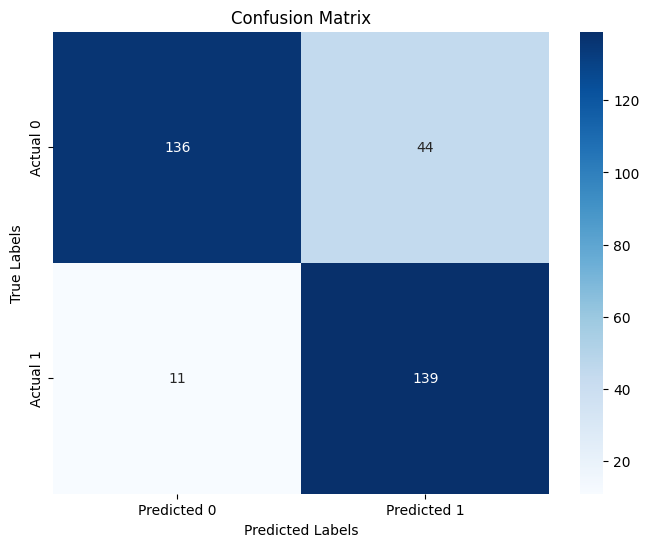

In [ ]:
# Confusion matrix with labels

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, predicted_labels_1d)

# Create a heatmap for the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()


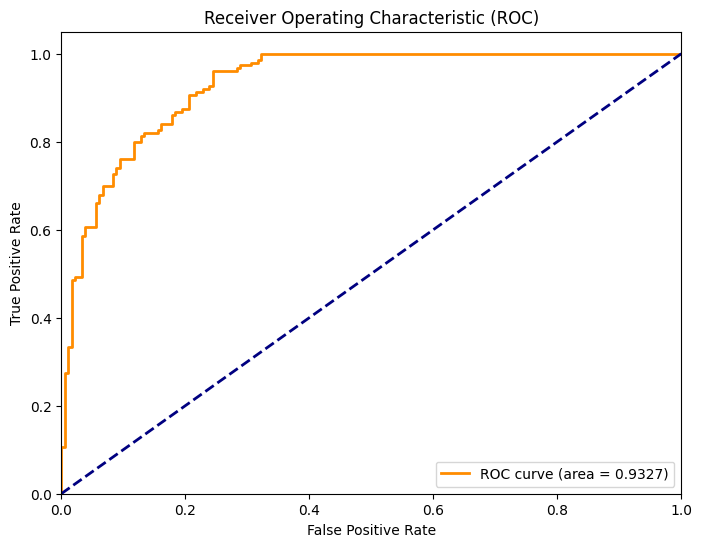

In [ ]:
# ROC-AUC score and AUC curve

from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, predictions)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc='lower right')
plt.show()



- **ROC Curve (Receiver Operating Characteristic Curve)**: A graphical plot that shows the performance of a binary classification model by plotting the **True Positive Rate (TPR)** against the **False Positive Rate (FPR)** at various threshold settings. (Notice that we choose 0.5 as our threshold for prediction.)

- **AUC (Area Under the Curve)**: A single scalar value that represents the **area under the ROC curve**. It measures the model's ability to distinguish between classes.
  - Ranges from 0 to 1.
  - **AUC = 1**: Perfect classifier.
  - **AUC = 0.5**: No discrimination (random guessing - dash line in above chart).
  - **Higher AUC** indicates **better model performance**.


Now let's compare our result with those of original paper! According to the original paper, they achieve the following results:

| Label      | Precision | Recall | F1-score |
|------------|-----------|--------|----------|
| nv         | 0.88      | 0.91   | 0.89     |
| mel        | 0.46      | 0.46   | 0.46     |
| bkl        | 0.53      | 0.41   | 0.46     |
| bcc        | 0.43      | 0.61   | 0.50     |
| akiec      | 0.53      | 0.31   | 0.39     |
| vasc       | 0.62      | 0.54   | 0.58     |
| df         | 1.00      | 0.05   | 0.10     |
| **accuracy**   |           |        | **0.76**  |
| **macro avg** | 0.64      | 0.47   | 0.48     |
| **weighted avg** | 0.76  | 0.76   | 0.76     |

Notice that their task is different from us: They did a 7-class classification task!

Their model achieve an accuracy of 0.76 on the test set, while ours achieves a test accuracy if 0.82. Moreover our models F1-scores (micro, macro, weighted) on test set are all greater than those in paper's model.


### Our modified version of this model
Here we go through the exact procedure, except our model is now changed:

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, BatchNormalization, Dropout

def build_cnn_from_table12(input_shape=(28, 28, 3), num_classes=2):
    model = Sequential(name="Our_model_with_BN_and_Dropout")

    model.add(Input(shape=input_shape))

    model.add(Conv2D(64, kernel_size=(3, 3), padding='same', activation='relu', name='conv2d_4_2'))
    model.add(BatchNormalization(name='bn_4'))
    model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2), name='max_pooling2d_4_2'))

    model.add(Conv2D(64, kernel_size=(3, 3), padding='same', activation='relu', name='conv2d_5_2'))
    model.add(BatchNormalization(name='bn_5'))
    model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2), name='max_pooling2d_5'))

    model.add(Conv2D(64, kernel_size=(3, 3), padding='same', activation='relu', name='conv2d_6_2'))
    model.add(BatchNormalization(name='bn_6'))
    model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2), padding='same', name='max_pooling2d_6_2'))

    model.add(Conv2D(128, kernel_size=(3, 3), padding='same', activation='relu', name='conv2d_7_2'))
    model.add(BatchNormalization(name='bn_7'))
    model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2), name='max_pooling2d_7_2'))

    model.add(Flatten(name='flatten_1_2'))

    model.add(Dense(64, activation='relu', name='dense_3_2'))
    model.add(BatchNormalization(name='bn_dense_3'))
    model.add(Dropout(0.1, name='dropout_dense_3'))

    model.add(Dense(32, activation='relu', name='dense_4_2'))
    model.add(BatchNormalization(name='bn_dense_4'))
    model.add(Dropout(0.1, name='dropout_dense_4'))

    model.add(Dense(1, activation='sigmoid', name='dense_5_2'))

    return model

# Build and summarize the model
model2 = build_cnn_from_table12(input_shape=(28, 28, 3), num_classes=2)
model2.summary()

Model: "Our_model_with_BN_and_Dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_4_2 (Conv2D)                  │ (None, 28, 28, 64)          │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bn_4 (BatchNormalization)            │ (None, 28, 28, 64)          │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4_2 (MaxPooling2D)     │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5_2 (Conv2D)                  │ (None, 14, 14, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bn_5 (BatchNormalization)            │ (None, 14, 14, 64)          │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 7, 7, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6_2 (Conv2D)                  │ (None, 7, 7, 64)            │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bn_6 (BatchNormalization)            │ (None, 7, 7, 64)            │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_6_2 (MaxPooling2D)     │ (None, 4, 4, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7_2 (Conv2D)                  │ (None, 4, 4, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bn_7 (BatchNormalization)            │ (None, 4, 4, 128)           │             512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_7_2 (MaxPooling2D)     │ (None, 2, 2, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1_2 (Flatten)                │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3_2 (Dense)                    │ (None, 64)                  │          32,832 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bn_dense_3 (BatchNormalization)      │ (None, 64)                  │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_dense_3 (Dropout)            │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4_2 (Dense)                    │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bn_dense_4 (BatchNormalization)      │ (None, 32)                  │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_dense_4 (Dropout)            │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5_2 (Dense)                    │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 186,113 (727.00 KB)

 Trainable params: 185,281 (723.75 KB)

 Non-trainable params: 832 (3.25 KB)

In [ ]:
optimizer = tf.keras.optimizers.Adam(0.001)

It is mentioned in the paper that they are Using these two callback! **However, they didn't mention specific hyperparameters of these callback!** Here, we set the hyperparameters manualy.

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Stop training if val_loss doesn't improve for 10 epochs
early_stopping = EarlyStopping(
    monitor='val_accuracy',
    patience=10,
    restore_best_weights=True
)

# Reduce learning rate if val_loss plateaus
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.6,      # Reduce LR by a factor of 0.8
    patience=5,      # Wait for 3 epochs before reducing LR
    min_lr=1e-6      # Don't go below this
)


In [ ]:
# Compile the model
model2.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
history2 = model2.fit(
    train_generator,
    epochs=50,  # Adjust the number of epochs as needed
    validation_data=val_generator,
    callbacks=[ reduce_lr],
    verbose=1
)



Epoch 1/50
83/83 ━━━━━━━━━━━━━━━━━━━━ 14s 83ms/step - accuracy: 0.7382 - loss: 0.5264 - val_accuracy: 0.6394 - val_loss: 0.6715 - learning_rate: 0.0010
Epoch 2/50
83/83 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.7900 - loss: 0.4171 - val_accuracy: 0.6273 - val_loss: 0.6457 - learning_rate: 0.0010
Epoch 3/50
83/83 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.8092 - loss: 0.3951 - val_accuracy: 0.7212 - val_loss: 0.6048 - learning_rate: 0.0010
Epoch 4/50
83/83 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.8114 - loss: 0.3775 - val_accuracy: 0.6152 - val_loss: 0.5845 - learning_rate: 0.0010
Epoch 5/50
83/83 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.8130 - loss: 0.3690 - val_accuracy: 0.6273 - val_loss: 0.7427 - learning_rate: 0.0010
Epoch 6/50
83/83 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.8107 - loss: 0.3893 - val_accuracy: 0.7848 - val_loss: 0.4639 - learning_rate: 0.0010
Epoch 7/50
83/83 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.8256 - loss: 0.3683 - val_ac

Now the training is done. We evaluate the performance of our model on the test set.(Notice that no augumentation is done on validation and test set!)

In [ ]:
# Evaluate the model on the test set
loss, accuracy = model2.evaluate(test_generator)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8870 - loss: 0.2619 
Test Loss: 0.2943
Test Accuracy: 0.8697


In [ ]:
# plot history using plotly

fig = px.line(history2.history, y=['loss', 'val_loss'], title="Loss vs Epochs")
fig.show()

fig = px.line(history2.history, y=['accuracy', 'val_accuracy'], title="Accuracy vs Epochs")
fig.show()


In [ ]:
# predict with model

predictions2 = model2.predict(test_generator)

# convert continious predictions to strict 0-1 predictions. (Notice sigmoid in final layer.)
predicted_labels2 = (predictions2 >= 0.5).astype(int)

# Convert the predicted_labels to a 1D list
predicted_labels_1d2 = predicted_labels2.flatten()

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step


Now, it's time to check other metrics as well. in the following cells, we check classification report(which shows several metrics, including precision, recall, f1-score, and accuracy), the confusion matrix(which shows a compact summary of the predictions of our model against the actual labels), and finally the ROC curve.

In [ ]:
# Classification report

from sklearn.metrics import classification_report

print(classification_report(y_test, predicted_labels_1d2 , digits = 4))


              precision    recall  f1-score   support

           0     0.9419    0.8111    0.8716       180
           1     0.8057    0.9400    0.8677       150

    accuracy                         0.8697       330
   macro avg     0.8738    0.8756    0.8697       330
weighted avg     0.8800    0.8697    0.8698       330



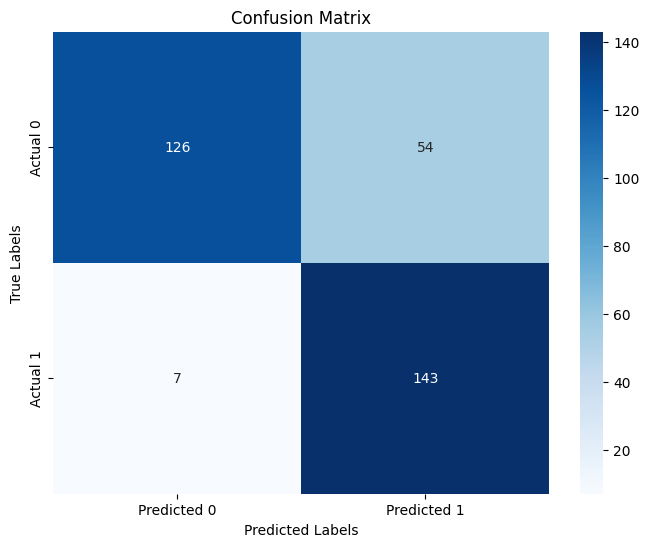

In [ ]:
# Confusion matrix with labels

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, predicted_labels_1d2)

# Create a heatmap for the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()


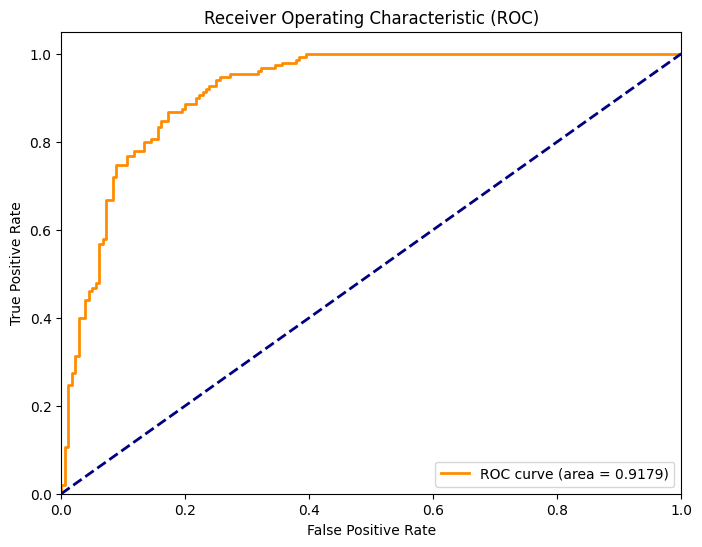

In [ ]:
# ROC-AUC score and AUC curve

from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, predictions2)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc='lower right')
plt.show()


#### How Batch Normalization and Dropout Improve Performance

- **Batch Normalization**:
  - Normalizes the output of layers to have zero mean and unit variance.
  - Stabilizes and speeds up training by reducing internal covariate shift.
  - Allows for higher learning rates and reduces sensitivity to initialization.

- **Dropout**:
  - Randomly sets a fraction of inputs to zero during training.
  - Prevents overfitting by forcing the network to learn redundant representations.
  - Acts as a regularizer and improves generalization on unseen data.


## Q1.6

**Model 1 vs. Model 2: Deeper Reasons for Performance Differences**

Beyond the direct metric comparisons, the superior performance of Model 2 stems from architectural choices that address fundamental challenges in training deep neural networks:

1.  **Gradient Stability and Faster Learning (Batch Normalization in Model 2):**
    * **Issue in Deep Networks:** As data propagates through many layers, the distribution of activations can shift (internal covariate shift). This makes training difficult as subsequent layers constantly need to adapt to changing input distributions. It can also lead to vanishing or exploding gradients, hindering learning.
    * **Batch Norm's Solution:** By normalizing the activations within each mini-batch, batch normalization stabilizes these distributions. This allows for the use of higher learning rates, leading to faster convergence and potentially better optimization of the network's weights. Stable gradients also ensure that information flows more effectively through the network during backpropagation.

2.  **Improved Generalization and Reduced Overfitting (Dropout in Model 2):**
    * **Overfitting Problem:** Deep models with many parameters can memorize the training data, performing well on it but poorly on unseen data. This is known as overfitting.
    * **Dropout's Role:** Dropout acts as a powerful regularizer by randomly deactivating neurons during training. This forces the network to learn redundant representations, meaning no single neuron becomes overly responsible for a specific feature. This makes the model more robust and less sensitive to the specifics of the training data, leading to better performance on unseen data (generalization).

3.  **Enhanced Feature Learning Capacity (Initial Filters in Model 2):**
    * **Early Feature Extraction:** The initial convolutional layers are crucial for learning low-level features (edges, textures, colors). Starting with more filters (64 in Model 2 vs. 16 in Model 1) allows the network to capture a richer and more diverse set of these fundamental features early on.
    * **Building Complexity:** These richer early features can then be combined and transformed by subsequent layers into more complex, high-level features that are more discriminative for the classification task. However, more filters also mean more parameters, increasing the risk of overfitting if not controlled by techniques like batch normalization and dropout.

4.  **More Robust Class Representations (Combined Effect in Model 2):**
    * **Synergistic Impact:** The combination of batch normalization and dropout in Model 2 likely leads to the learning of more robust and reliable feature representations for each class. Batch normalization ensures stable learning of these features, while dropout prevents the model from relying too heavily on any single feature, making the learned representations more generalizable. This can explain the improved precision and recall for specific classes in Model 2, as it learns more distinctive characteristics for each category.

In essence, Model 2's architectural enhancements are designed to make the training process more stable and the resulting model more capable of generalizing to unseen data by learning more robust and less overfit feature representations. This translates into the observed improvements in accuracy and the balanced performance across precision and recall.

| Metric       | Model 1 | Model 2 | Change (Model 2 - Model 1) | Interpretation                                                                 |
|--------------|---------|---------|----------------------------|------------------------------------------------------------------------------|
| **Accuracy** | 0.8333  | 0.8697  | +0.0364                    | Model 2 is significantly more accurate overall.                               |
| **Precision**|         |         |                            |                                                                              |
| Class 0      | 0.9252  | 0.9419  | +0.0167                    | Model 2 is slightly better at correctly predicting class 0.                  |
| Class 1      | 0.7596  | 0.8057  | +0.0461                    | Model 2 is better at correctly predicting class 1.                             |
| **Recall** |         |         |                            |                                                                              |
| Class 0      | 0.7556  | 0.8111  | +0.0555                    | Model 2 is better at identifying all actual instances of class 0.             |
| Class 1      | 0.9267  | 0.9400  | +0.0133                    | Model 2 is slightly better at identifying all actual instances of class 1.    |
| **F1-score** |         |         |                            |                                                                              |
| Class 0      | 0.8318  | 0.8716  | +0.0398                    | Model 2 has a better balance of precision and recall for class 0.             |
| Class 1      | 0.8348  | 0.8677  | +0.0329                    | Model 2 has a better balance for class 1.                                   |
| **Macro Avg**|         |         |                            |                                                                              |
| Precision    | 0.8424  | 0.8738  | +0.0314                    | Model 2 has better average precision across both classes.                     |
| Recall       | 0.8411  | 0.8756  | +0.0345                    | Model 2 has better average recall across both classes.                        |
| F1-score     | 0.8333  | 0.8697  | +0.0364                    | Model 2 has a better overall balanced performance across classes.             |
| **Weighted Avg**|        |         |                            |                                                                              |
| Precision    | 0.8499  | 0.8800  | +0.0301                    | Model 2 has better weighted average precision.                                |
| Recall       | 0.8333  | 0.8697  | +0.0364                    | Model 2 has better weighted average recall.                                   |
| F1-score     | 0.8332  | 0.8698  | +0.0366                    | Model 2 has better weighted average balanced performance.                     |

## Q1.7(Optional)

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, BatchNormalization,
    Dropout, GlobalAveragePooling2D, Dense
)

def build_stronger_cnn(input_shape=(128 , 128, 3), num_classes=2):
    model = Sequential(name="Improved_CNN_SkinCancer")

    model.add(Input(shape=input_shape))

    # Block 1
    model.add(Conv2D(32, (3, 3), activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(Conv2D(32, (3, 3), activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(MaxPooling2D((2, 2)))

    # Block 2
    model.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(MaxPooling2D((2, 2)))

    # Block 3
    model.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(MaxPooling2D((2, 2)))

    # Block 4
    model.add(Conv2D(256, (3, 3), activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(Conv2D(256, (3, 3), activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(MaxPooling2D((2, 2)))

    # Global Average Pooling
    model.add(GlobalAveragePooling2D())

    # Fully connected layers
    model.add(Dense(128, activation='relu'))
    model.add(Dropout(0.1))

    model.add(Dense(64, activation='relu'))
    model.add(Dropout(0.1))

    # Output layer for binary classification
    model.add(Dense(1, activation='sigmoid'))

    return model


# Build the model
model3 = build_stronger_cnn()

# Print the model summary to verify the architecture
model3.summary()

Model: "Improved_CNN_SkinCancer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 128, 128, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 128, 128, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 128, 128, 32)        │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 128, 128, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 64, 64, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 64, 64, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 64, 64, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 64, 64, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 32, 32, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 32, 32, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 32, 32, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_5                │ (None, 32, 32, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (None, 16, 16, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_6                │ (None, 16, 16, 256)         │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 16, 16, 256)         │         590,0

 Total params: 1,217,313 (4.64 MB)

 Trainable params: 1,215,393 (4.64 MB)

 Non-trainable params: 1,920 (7.50 KB)

Now, we do the same training with our model. Instead of the previous callbacks, we just use a better optimizer(Nadam) and learning scheduling technique!

In [ ]:
X_train_org = tf.image.resize(X_train_org, (128, 128)).numpy()
X_val_org = tf.image.resize(X_val_org, (128, 128)).numpy()
X_test_org = tf.image.resize(X_test_org, (128, 128)).numpy()


In [ ]:
# Create an ImageDataGenerator for training data with augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,                # Normalize pixel values to the [0, 1] range
    rotation_range=20,            # Randomly rotate images by up to ±20 degrees
    width_shift_range=0.2,        # Randomly shift images horizontally by up to 20% of width
    height_shift_range=0.2,       # Randomly shift images vertically by up to 20% of height
    shear_range=0.2,              # Apply random shear transformations (slant the image)
    zoom_range=0.2,               # Randomly zoom in or out by up to 20%
    horizontal_flip=True,         # Randomly flip images horizontally (left-right)
    fill_mode='nearest'           # Fill in missing pixels after transformation using nearest pixel values
)

val_datagen = ImageDataGenerator(
    rescale=1./255,                # Normalize pixel values to the [0, 1] range
)
test_datagen = ImageDataGenerator(
    rescale=1./255,                # Normalize pixel values to the [0, 1] range
)

# Load the training data with augmentation
train_generator = train_datagen.flow(
    X_train_org, y_train,
    batch_size=32,
    shuffle=True
)

val_generator = val_datagen.flow(
    X_val_org, y_val,
    batch_size=32,
    shuffle=False
)

test_generator = test_datagen.flow(
    X_test_org, y_test,
    shuffle=False
)


In [ ]:
import math
# Compile the model with Nadam optimizer and learning rate scheduler
optimizer3 = tf.keras.optimizers.Nadam(learning_rate=0.001)  # Initial learning rate

def lr_scheduler(epoch, lr):
    if epoch < 10:
        return lr
    else:
        # Directly compute float using math.exp
        return lr * math.exp(-0.1)


lr_callback = tf.keras.callbacks.LearningRateScheduler(lr_scheduler)
# Compile the model
model3.compile(optimizer=optimizer3, loss='binary_crossentropy', metrics=['accuracy'])

# Train the model with the new optimizer and callback
history3 = model3.fit(
    train_generator,
    epochs=50,
    validation_data=val_generator,
    callbacks=[lr_callback], # removed early_stopping and reduce_lr
    verbose=1
)




/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning:

Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.



Epoch 1/50
83/83 ━━━━━━━━━━━━━━━━━━━━ 53s 284ms/step - accuracy: 0.7344 - loss: 0.5407 - val_accuracy: 0.5455 - val_loss: 1.2806 - learning_rate: 0.0010
Epoch 2/50
83/83 ━━━━━━━━━━━━━━━━━━━━ 12s 142ms/step - accuracy: 0.7993 - loss: 0.4167 - val_accuracy: 0.5455 - val_loss: 0.6985 - learning_rate: 0.0010
Epoch 3/50
83/83 ━━━━━━━━━━━━━━━━━━━━ 11s 133ms/step - accuracy: 0.8242 - loss: 0.3899 - val_accuracy: 0.5636 - val_loss: 0.6693 - learning_rate: 0.0010
Epoch 4/50
83/83 ━━━━━━━━━━━━━━━━━━━━ 23s 163ms/step - accuracy: 0.8143 - loss: 0.3791 - val_accuracy: 0.7030 - val_loss: 0.5759 - learning_rate: 0.0010
Epoch 5/50
83/83 ━━━━━━━━━━━━━━━━━━━━ 12s 145ms/step - accuracy: 0.8229 - loss: 0.3855 - val_accuracy: 0.7545 - val_loss: 0.4724 - learning_rate: 0.0010
Epoch 6/50
83/83 ━━━━━━━━━━━━━━━━━━━━ 12s 146ms/step - accuracy: 0.8268 - loss: 0.3699 - val_accuracy: 0.7455 - val_loss: 0.5792 - learning_rate: 0.0010
Epoch 7/50
83/83 ━━━━━━━━━━━━━━━━━━━━ 21s 146ms/step - accuracy: 0.8164 - loss: 0.

NameError: name 'loss2' is not defined

In [ ]:

# Evaluate the model on the test set
loss3, accuracy3 = model3.evaluate(test_generator)
print(f"Test Loss: {loss3:.4f}")
print(f"Test Accuracy: {accuracy3:.4f}")

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8635 - loss: 0.3012
Test Loss: 0.3245
Test Accuracy: 0.8576


In [ ]:

fig = px.line(history3.history, y=['loss', 'val_loss'], title="Loss vs Epochs")
fig.show()

fig = px.line(history3.history, y=['accuracy', 'val_accuracy'], title="Accuracy vs Epochs")
fig.show()


As you can see in the above plot, Unlike the previous methods there's no sign of overfitting in the training step which is quitely good

In [ ]:

# Predict on the test data
predictions3 = model3.predict(test_generator)
predicted_labels3 = (predictions3 >= 0.5).astype(int)

# Convert the predicted_labels to a 1D list
predicted_labels_1d3 = predicted_labels3.flatten()


11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 93ms/step


In [ ]:

from sklearn.metrics import classification_report

print(classification_report(y_test, predicted_labels_1d3 , digits = 4))


              precision    recall  f1-score   support

           0     0.9030    0.8278    0.8638       180
           1     0.8121    0.8933    0.8508       150

    accuracy                         0.8576       330
   macro avg     0.8576    0.8606    0.8573       330
weighted avg     0.8617    0.8576    0.8579       330



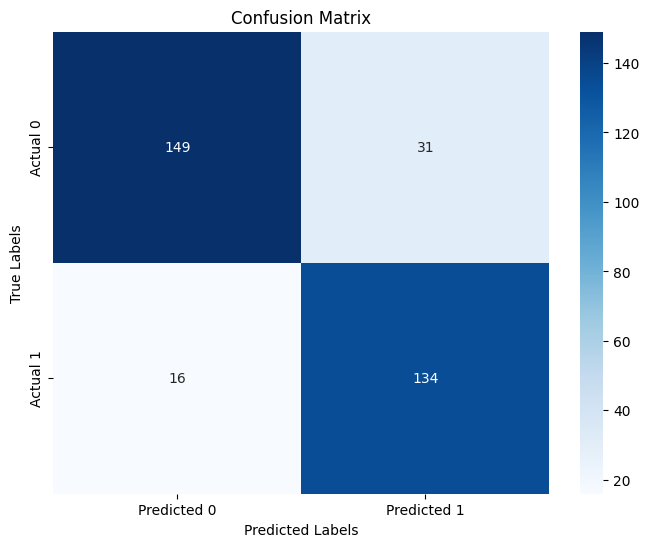

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, predicted_labels_1d3)

# Create a heatmap for the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()


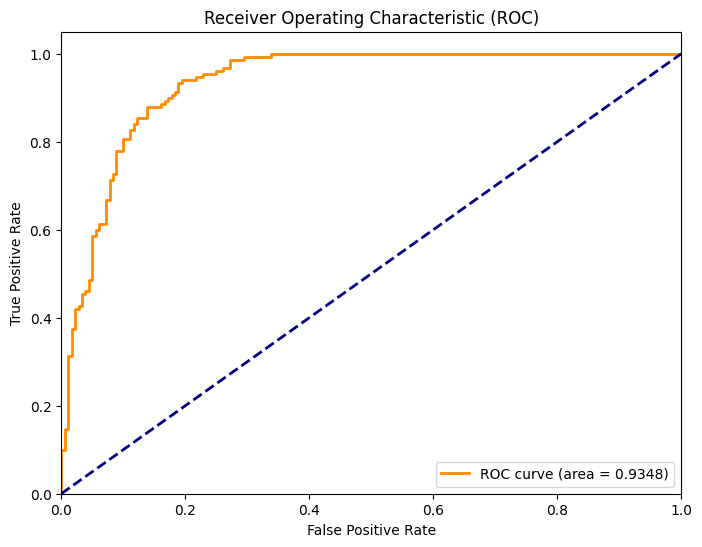

In [ ]:

from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, predictions3)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc='lower right')
plt.show()


Our model differs from the paper's model in the following points:
1. We are using deeper network! The base model has around 132,385 learnable parameters, while our model has about 1,215,393 parameters.(around 9x more parameters.)
2. We are using Batch normalization and dropout for better generalization and more stable learning phase. As you can see, our training metrics are more stable during epochs.
3. more expochs: since we don't use early stopping, we continue the learning phase for longer period.
4. Different optimizer: we change our optimizer to Nadam. In our previous experiments, Nadam performs better on Adam (generally speaking), so we choose Nadam. Also, we use an exponential learning rate scheduling to reduce the learning rate over time, leading to more stable learning and not fluctuating.
5. Larger inputs: we use (64,64,3) images instead of (28,28,3) to have more reciptive field and less information loss.


All these modifications together help our model to perform better than the paper's model.
Also notive that the paper's model has a huge overfitting (difference between training and test accuracy and loss), but in our model, this gap is less, and our model does not overfit as much as the previos model.